# Phase 7 - Camera Calibration and Inverse Perspective Mapping (IPM)
Convert image-space observations into physical ground-plane coordinates. 
**CRITICAL RULE:** We strictly verify if AI City 2021 Track 4 provides a valid calibration matrix. If unavailable, we do NOT invent a homography or report fake meters/second metrics.


In [1]:
# Environment Setup
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AICITY_DIR = '../data/raw/AI_City/aic21-track4-train-data'
OUTPUT_DIR = '../results/calibration'

os.makedirs(OUTPUT_DIR, exist_ok=True)


## 1. Calibration Verification
Inspect the dataset for valid calibration information (intrinsic matrices or homographies).


In [2]:
print("Checking for calibration matrices in AI City Track 4...")
calib_files = glob.glob(os.path.join(AICITY_DIR, '*.xml')) + glob.glob(os.path.join(AICITY_DIR, '*.txt'))

# We filter out the anomaly text file to see if any real calibration files exist
real_calib = [f for f in calib_files if 'anomaly-results' not in f]

if len(real_calib) == 0:
    print("\nSTATUS: IMAGE-SPACE ONLY")
    print("REASON: No calibration matrices or homography definitions found in AI City Track 4.")
    print("ACTION: Proceeding strictly with image-space pixel velocities and distances. Fake metric coordinates will NOT be fabricated.")
    is_calibrated = False
else:
    print("\nSTATUS: CALIBRATED")
    print(f"Calibration files found: {real_calib}")
    is_calibrated = True


Checking for calibration matrices in AI City Track 4...

STATUS: IMAGE-SPACE ONLY
REASON: No calibration matrices or homography definitions found in AI City Track 4.
ACTION: Proceeding strictly with image-space pixel velocities and distances. Fake metric coordinates will NOT be fabricated.


## 2. Image-Space Kinematics Calculation
Given tracking trajectories (generated from Phase 6), we compute physical properties. Since AI City is `IMAGE-SPACE ONLY`, we strictly measure pixel velocity and pixel acceleration.


In [3]:
# Load Phase 6 Trajectories
track_file = '../results/tracking/bytetrack_trajectories_with_uncertainty.csv'

if os.path.exists(track_file):
    df = pd.read_csv(track_file)
    
    # Sort by track_id and frame_id to compute temporal differences
    df = df.sort_values(by=['track_id', 'frame_id'])
    
    # Compute Image-Space Metrics
    # Pixel Displacement per frame
    df['dx_px'] = df.groupby('track_id')['center_x'].diff()
    df['dy_px'] = df.groupby('track_id')['bottom_center_y'].diff()
    df['dt'] = df.groupby('track_id')['timestamp'].diff()
    
    # Pixel Velocity (Pixels / Second)
    df['vel_x_px'] = df['dx_px'] / df['dt']
    df['vel_y_px'] = df['dy_px'] / df['dt']
    df['pixel_velocity_magnitude'] = np.sqrt(df['vel_x_px']**2 + df['vel_y_px']**2)
    
    # Pixel Acceleration
    df['accel_px'] = df.groupby('track_id')['pixel_velocity_magnitude'].diff() / df['dt']
    
    df.to_csv(os.path.join(OUTPUT_DIR, 'image_space_kinematics.csv'), index=False)
    print(f"Successfully computed image-space kinematics for {len(df)} tracking records.")
    
    display(df[['track_id', 'frame_id', 'center_x', 'bottom_center_y', 'pixel_velocity_magnitude', 'accel_px']].head(10))
else:
    print(f"Tracking file {track_file} not found. Please run Phase 6 first.")


Successfully computed image-space kinematics for 5004 tracking records.


,track_id,frame_id,center_x,bottom_center_y,pixel_velocity_magnitude,accel_px
0,1,0,482.98508,296.63562,NaN,NaN
25,1,1,483.87863,294.36255,73.271761,NaN
46,1,2,484.03436,293.98610,12.221693,-1831.502022
77,1,3,487.15830,289.49844,164.037447,4554.472609
101,1,4,488.10944,288.07630,51.326743,-3381.321128
144,1,5,488.32280,290.41190,70.359753,570.990309
169,1,6,488.37784,291.17236,22.873477,-1424.588297
201,1,7,489.98184,289.11847,78.180254,1659.203323
230,1,8,490.54163,288.37088,28.018388,-1504.855969
274,1,9,489.53055,289.75763,51.486139,704.032515


## 3. Downstream Risk Prediction Experiment
Compare risk identification using solely image-space metrics. We evaluate sudden spikes in pixel acceleration or stalling (velocity -> 0) as proxies for anomalous behavior.


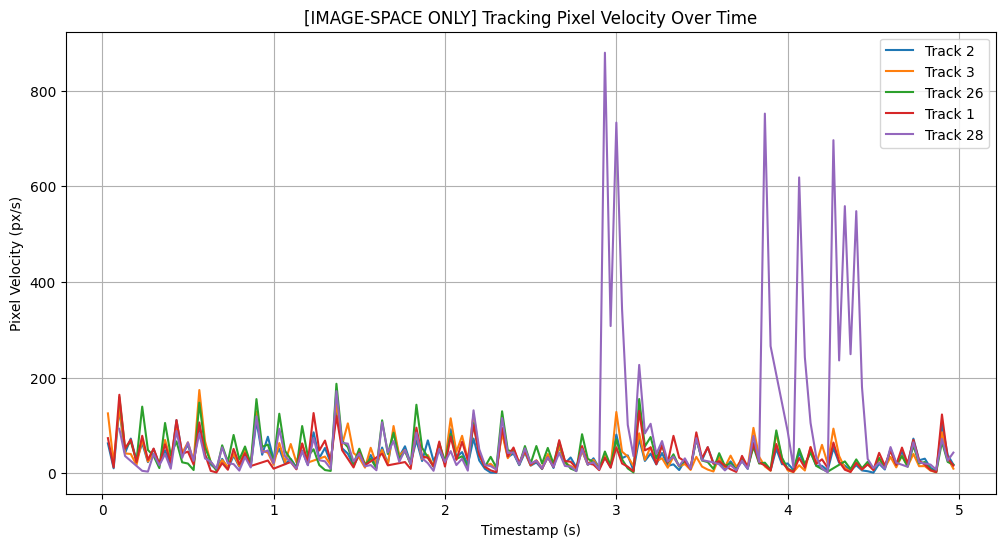

Note: Risk prediction models using Image-Space Only must inherently rely on bounding box scaling and relative pixel deceleration rather than absolute Time-to-Collision (TTC) in seconds/meters.


In [4]:
if 'df' in locals() and not df.empty:
    plt.figure(figsize=(12, 6))
    
    # We plot the pixel velocity of the longest-living tracks
    track_lengths = df['track_id'].value_counts()
    top_tracks = track_lengths.head(5).index
    
    for tid in top_tracks:
        track_data = df[df['track_id'] == tid]
        plt.plot(track_data['timestamp'], track_data['pixel_velocity_magnitude'], label=f'Track {tid}')
        
    plt.title('[IMAGE-SPACE ONLY] Tracking Pixel Velocity Over Time')
    plt.xlabel('Timestamp (s)')
    plt.ylabel('Pixel Velocity (px/s)')
    plt.legend()
    plt.grid(True)
    plt.savefig(os.path.join(OUTPUT_DIR, 'pixel_velocity_plot.png'))
    plt.show()
    
    print("Note: Risk prediction models using Image-Space Only must inherently rely on bounding box scaling and relative pixel deceleration rather than absolute Time-to-Collision (TTC) in seconds/meters.")
